# 01 · Country statistics: price levels, net earnings and exchange rates

**Owner:** Luca · **Step 1** (deadline 11 Nov 2026)

This notebook collects three country-level datasets via Web APIs. They are needed for the price comparisons (SQ3) and the *working hours per ski pass* index (SQ4):

| Data | Source | API |
| --- | --- | --- |
| Price level index (PLI), EU27 = 100 | Eurostat `prc_ppp_ind` | Eurostat dissemination API (via the `eurostat` Python package) |
| Annual net earnings of an average worker | Eurostat `earn_nt_netft` | same |
| EUR/CHF exchange rate, daily | Frankfurter (ECB reference rates) | REST API, no key |

Output: `data/processed/country_stats.csv` and `data/processed/fx_eur_chf_daily.csv`.

## 1. Setup

In [14]:
import requests                 # sends requests to web APIs
import pandas as pd             # tables (DataFrames)
import matplotlib.pyplot as plt # charts
import eurostat                 # small library that talks to the Eurostat API
from pathlib import Path        # handles folder paths

COUNTRIES = ["CH", "IT", "AT", "FR"]   # ISO codes of the four countries
HOURS_PER_YEAR = 1760                  # assumption: 220 working days x 8 hours (same for all countries)

OUT = Path("../data/processed")        # where we save the results
OUT.mkdir(parents=True, exist_ok=True)

## 2. Price level index (Eurostat `prc_ppp_ind`)

- `na_item = PLI_EU27_2020`: price level index, EU27 average = 100 (e.g. 170 = prices 70 % above the EU average)
- `ppp_cat = A01`: *actual individual consumption*, i.e. the general cost of living

In [15]:
pli_raw = eurostat.get_data_df(
    "prc_ppp_ind",
    filter_pars={"geo": COUNTRIES, "na_item": ["PLI_EU27_2020"], "ppp_cat": ["A01"]},
)
pli_raw.head()

,freq,na_item,ppp_cat,geo\TIME_PERIOD,1995,1996,1997,1998,1999,2000,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,A,PLI_EU27_2020,A01,CH,152.8,147.1,139.3,141.3,141.8,146.4,...,177.5,176.0,175.3,168.8,174.9,182.2,175.9,182.4,183.7,184.3
1,A,PLI_EU27_2020,A01,IT,89.0,98.6,101.8,101.1,102.1,102.8,...,106.7,105.3,104.7,104.4,102.9,102.6,102.2,100.6,98.4,98.1
2,A,PLI_EU27_2020,A01,AT,119.5,115.4,113.2,111.9,112.4,110.7,...,114.0,115.2,116.4,117.2,118.2,118.9,115.4,115.1,117.9,119.7
3,A,PLI_EU27_2020,A01,FR,116.8,115.5,113.2,113.1,112.3,109.8,...,110.5,110.2,110.6,110.9,109.6,108.9,110.4,109.5,109.1,107.9


In [16]:
def wide_to_long(df, value_name):
    """Eurostat gives one column per year. Turn it into one row per country and year."""
    year_cols = [c for c in df.columns if str(c).strip()[:4].isdigit()]
    geo_col = [c for c in df.columns if str(c).startswith("geo")][0]
    long = df.melt(id_vars=[c for c in df.columns if c not in year_cols],
                   value_vars=year_cols, var_name="year", value_name=value_name)
    long = long.rename(columns={geo_col: "country"})
    long["year"] = long["year"].astype(str).str.strip().str[:4].astype(int)
    return long.dropna(subset=[value_name])

pli = wide_to_long(pli_raw, "pli_eu27")[["country", "year", "pli_eu27"]]
pli[pli["year"] >= 2019].pivot(index="year", columns="country", values="pli_eu27")

country,AT,CH,FR,IT
year,,,,
2019,118.2,174.9,109.6,102.9
2020,118.9,182.2,108.9,102.6
2021,115.4,175.9,110.4,102.2
2022,115.1,182.4,109.5,100.6
2023,117.9,183.7,109.1,98.4
2024,119.7,184.3,107.9,98.1


## 3. Net earnings (Eurostat `earn_nt_netft`)

We want: **net** earnings, **single person without children earning 100 % of the average wage**, in **EUR**.
The codes are looked up by their labels, and the full list is printed so that we can check the choice.

In [17]:
# earn_nt_net = annual net earnings in EUR, by type of household
wage_raw = eurostat.get_data_df("earn_nt_net", filter_pars={"geo": COUNTRIES})
dims = [c for c in wage_raw.columns if not str(c).strip()[:4].isdigit()]
for c in dims:
    print(c, "->", sorted(wage_raw[c].astype(str).unique()))

freq -> ['A']
currency -> ['EUR', 'NAC', 'PPS']
estruct -> ['FAM', 'GRS', 'NET', 'SOC', 'TAX', 'TOTAL']
ecase -> ['CPL_CH2_AW100', 'CPL_CH2_AW100_100', 'CPL_CH2_AW100_33', 'CPL_CH2_AW100_67', 'CPL_NCH_AW100_100', 'CPL_NCH_AW100_33', 'P1_CH2_AW67', 'P1_NCH_AW100', 'P1_NCH_AW125', 'P1_NCH_AW167', 'P1_NCH_AW50', 'P1_NCH_AW67', 'P1_NCH_AW80']
geo\TIME_PERIOD -> ['AT', 'CH', 'FR', 'IT']


In [18]:
# list all household types, one per line, so we can read them
ecase_codes = sorted(wage_raw["ecase"].astype(str).unique())
for e in ecase_codes:
    print(e)

# single person, no children, 100% of the average wage
ECASE = "P1_NCH_AW100"
print("\nIs", ECASE, "available?", ECASE in ecase_codes)

wage_sel = wage_raw[
    (wage_raw["currency"] == "EUR")
    & (wage_raw["estruct"] == "NET")
    & (wage_raw["ecase"] == ECASE)
]
wage = wide_to_long(wage_sel, "net_earnings_year_eur")[["country", "year", "net_earnings_year_eur"]]
wage["net_earnings_hour_eur"] = wage["net_earnings_year_eur"] / HOURS_PER_YEAR
wage[wage["year"] >= 2019].pivot(index="year", columns="country", values="net_earnings_year_eur").round(0)

CPL_CH2_AW100
CPL_CH2_AW100_100
CPL_CH2_AW100_33
CPL_CH2_AW100_67
CPL_NCH_AW100_100
CPL_NCH_AW100_33
P1_CH2_AW67
P1_NCH_AW100
P1_NCH_AW125
P1_NCH_AW167
P1_NCH_AW50
P1_NCH_AW67
P1_NCH_AW80

Is P1_NCH_AW100 available? True


country,AT,CH,FR,IT
year,,,,
2019,32325.0,68324.0,28154.0,21500.0
2020,33032.0,72035.0,27472.0,22508.0
2021,33712.0,73724.0,28650.0,23512.0
2022,36076.0,78453.0,30241.0,23839.0
2023,38376.0,82060.0,31574.0,24593.0
2024,41159.0,NaN,31784.0,26593.0
2025,42347.0,NaN,32346.0,27788.0


## 4. EUR/CHF exchange rate (Frankfurter API)

In [19]:
url = "https://api.frankfurter.dev/v1/2010-01-01..2025-12-31"
response = requests.get(url, params={"base": "EUR", "symbols": "CHF"}, timeout=60)
response.raise_for_status()          # stops here with an error message if the request failed
data = response.json()               # the answer is JSON: {"base": "EUR", "rates": {"2010-01-04": {"CHF": 1.48}, ...}}

fx = pd.DataFrame([{"date": d, "eur_chf": v["CHF"]} for d, v in data["rates"].items()])
fx["date"] = pd.to_datetime(fx["date"])
print(len(fx), "rows from", fx["date"].min().date(), "to", fx["date"].max().date())
fx.tail()

4098 rows from 2009-12-31 to 2025-12-31


,date,eur_chf
4093,2025-12-23,0.9287
4094,2025-12-24,0.9284
4095,2025-12-29,0.9293
4096,2025-12-30,0.9293
4097,2025-12-31,0.9314


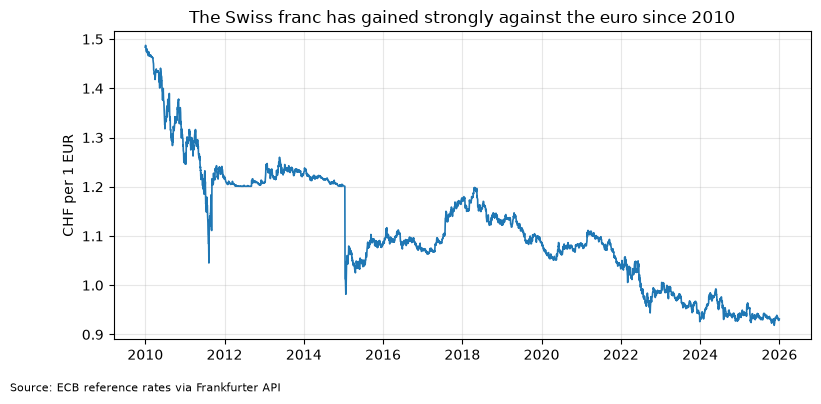

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fx["date"], fx["eur_chf"], linewidth=1.2)
ax.set_title("The Swiss franc has gained strongly against the euro since 2010")
ax.set_ylabel("CHF per 1 EUR")
ax.set_xlabel("")
ax.grid(alpha=0.3)
fig.text(0.01, -0.02, "Source: ECB reference rates via Frankfurter API", fontsize=8)
plt.show()

## 5. Combine and save

`country_stats` = one row per country and year with price level and earnings. It will become a table in the SQLite database in step 3.

In [21]:
country_stats = pli.merge(wage, on=["country", "year"], how="outer").sort_values(["country", "year"])

# integration check (needed for the integration log)
print("PLI rows:", len(pli), "| wage rows:", len(wage), "| merged rows:", len(country_stats))
print("Rows with both values:", country_stats.dropna().shape[0])

latest = country_stats.dropna().groupby("country")["year"].max()
print("\nLatest year with both values per country:")
print(latest)

country_stats.to_csv(OUT / "country_stats.csv", index=False)
fx.to_csv(OUT / "fx_eur_chf_daily.csv", index=False)
print("\nSaved:", OUT / "country_stats.csv", "and", OUT / "fx_eur_chf_daily.csv")

PLI rows: 120 | wage rows: 102 | merged rows: 123
Rows with both values: 99

Latest year with both values per country:
country
AT    2024
CH    2023
FR    2024
IT    2024
Name: year, dtype: int64

Saved: ../data/processed/country_stats.csv and ../data/processed/fx_eur_chf_daily.csv


## 6. Quick check: what does one hour of work buy?

Latest common year. This is only a first look; the real index (SQ4) uses the scraped ski-pass prices.

In [22]:
year = int(latest.min())
snap = country_stats[country_stats["year"] == year].set_index("country")
snap[["pli_eu27", "net_earnings_year_eur", "net_earnings_hour_eur"]].round(1)

,pli_eu27,net_earnings_year_eur,net_earnings_hour_eur
country,,,
AT,117.9,38375.9,21.8
CH,183.7,82060.1,46.6
FR,109.1,31573.5,17.9
IT,98.4,24592.5,14.0


## Notes for the integration log

- Join key: `country` (ISO code) + `year`.
- Record numbers lost/gained are printed in section 5.
- Assumption: 1,760 working hours per year in all four countries (real weekly hours differ, e.g. France 35 h). To be mentioned as a limitation.